In [251]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *
from scipy import ndimage
from adc_ctrl import *

### Lab Images
first starting with lab images because they're cleaner, and I'm sure I'm going to have to adapt a few things to work with the real images vs the simulated ones.

[-5.  -4.8 -4.6 -4.4 -4.2 -4.  -3.8 -3.6 -3.4 -3.2 -3.  -2.8 -2.6 -2.4
 -2.2 -2.  -1.8 -1.6 -1.4 -1.2 -1.  -0.8 -0.6 -0.4 -0.2  0.   0.2  0.4
  0.6  0.8  1.   1.2  1.4  1.6  1.8  2.   2.2  2.4  2.6  2.8  3.   3.2
  3.4  3.6  3.8  4.   4.2  4.4  4.6  4.8  5. ]


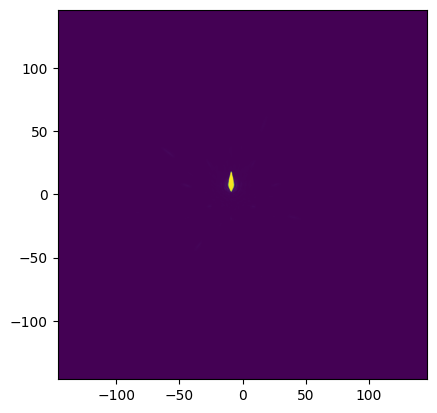

In [252]:
#import lab images
lab_sat = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
imshow_field(lab_sat[0])
angs = np.loadtxt('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.txt')
print(angs)

In [306]:
def window_field(data, center, width, height, pad_value=0.0):
    # 1. Find nearest pixel index for target center
    indx = data.grid.closest_to(center)
    ny_in, nx_in = data.shaped.shape
    y_ind, x_ind = np.unravel_index(indx, (ny_in, nx_in))

    # 2. Compute ideal slice bounds
    x_min_ideal = x_ind - width // 2
    x_max_ideal = x_min_ideal + width
    y_min_ideal = y_ind - height // 2
    y_max_ideal = y_min_ideal + height

    # 3. Clamp bounds to valid image indices
    x_min_valid = max(0, x_min_ideal)
    x_max_valid = min(nx_in, x_max_ideal)
    y_min_valid = max(0, y_min_ideal)
    y_max_valid = min(ny_in, y_max_ideal)

    # 4. Map valid patch into output array
    out_x_min = x_min_valid - x_min_ideal
    out_x_max = out_x_min + (x_max_valid - x_min_valid)
    out_y_min = y_min_valid - y_min_ideal
    out_y_max = out_y_min + (y_max_valid - y_min_valid)

    # 5. Allocate output crop array filled with pad_value
    cutout = np.full((height, width), pad_value, dtype=data.shaped.dtype)

    if (x_max_valid > x_min_valid) and (y_max_valid > y_min_valid):
        cutout[out_y_min:out_y_max, out_x_min:out_x_max] = data.shaped[
            y_min_valid:y_max_valid, x_min_valid:x_max_valid
        ]

    # 6. Construct sub_grid matching original syntax, shifted to center
    dx = data.grid.delta[0]
    dy = data.grid.delta[1]
    sub_grid = make_pupil_grid([width, height], [width * dx, height * dy])

    return Field(cutout.ravel(), sub_grid)

def crop_image(image, extent=100, mask_diam=0.5e-6):
    """Cuts out a centered PSF with the central core masked."""
    img_max = np.max(image)
    if img_max > 0:
        img_normalized = image / img_max
    else:
        img_normalized = image

    img_subtracted = img_normalized > 0.1
    total_sig = np.sum(img_subtracted)

    if total_sig > 0:
        center_of_intensity = np.array([
            np.sum(img_subtracted * img_subtracted.grid.x) / total_sig,
            np.sum(img_subtracted * img_subtracted.grid.y) / total_sig,
        ])
    else:
        center_of_intensity = np.array([0.0, 0.0])

    # Mask central core
    mask_ap = make_circular_aperture(mask_diam, center_of_intensity)
    mask = np.abs(mask_ap(img_subtracted.grid) - 1.0)
    image = mask * image

    # Safe padded crop
    image = window_field(image, center_of_intensity, extent, extent)

    # Vectorised non-negativity floor
    return np.maximum(image, 0.0)

In [254]:
def speckle_cutout(img,speckle_number,angle,f=10,window_size=30,search_extent=20):
    #note that this version is slightly different than the _testing notebook version
    #because it assumes the grid is in units of lam/D instead of pixel angular size!

    extent=search_extent
    separation = f 

    speckle_coords = np.array([
        [0,           separation],
        [separation,  0],
        [0,          -separation],
        [-separation, 0]
    ])
    speckle_center = speckle_coords[speckle_number]
    rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-angle))(img.grid)
    speckle_img = rect * img.copy()

    max_pixel = speckle_img.grid[np.argmax(speckle_img)]
    new_img = window_field(img,[max_pixel[0],max_pixel[1]],window_size,window_size)
    return np.array(new_img.shaped)

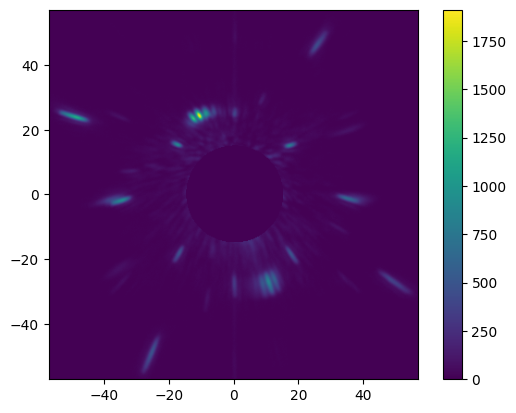

In [255]:
#crop it down and cut out a speckle
angle = 28
f = 47

img = lab_sat[-1]

cropped = crop_image(img,400,mask_diam=30)

#background subtraction
bg = np.median(cropped)
cropped -= bg
cropped[cropped <0] = 0

speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)

imshow_field(cropped)
plt.colorbar()

Text(0.5, 1.0, 'angle: 67.07')

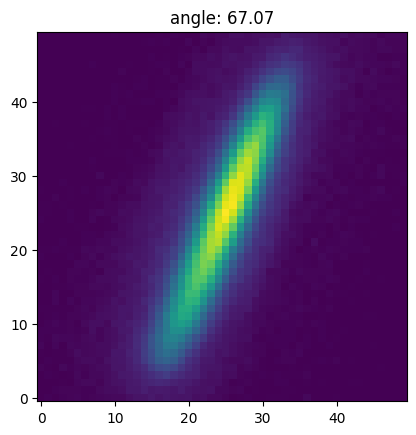

In [256]:
angle = moment_angle(speckle2)

plt.imshow(speckle2,origin='lower')
plt.title(f'angle: {angle:.2f}')

In [257]:
#iterate through the whole cube with all four spots and plot their angles + subtracted pointing pairs
angles0 = np.zeros(len(lab_sat))
angles2 = np.zeros_like(angles0)

angle = 28
f = 47


for i, img in enumerate(lab_sat):
    cropped = crop_image(img,400,mask_diam=30)

    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)

    angles0[i] = moment_angle(speckle0)
    angles2[i] = moment_angle(speckle2)


67.06866421447384


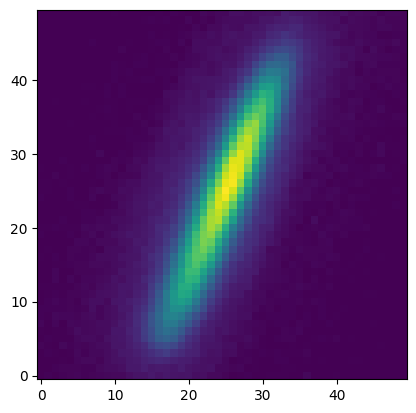

In [258]:
plt.imshow(speckle2,origin='lower')
print(angles2[-1])

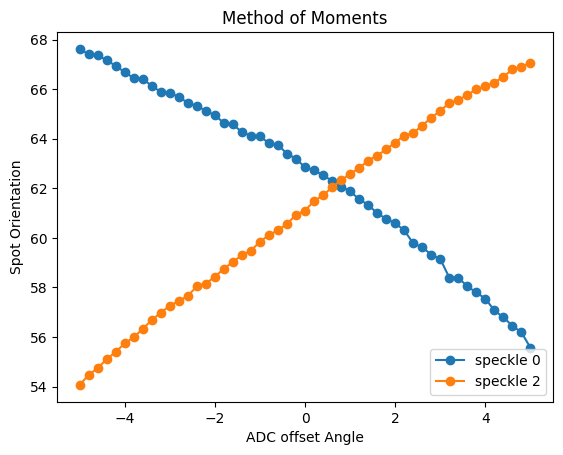

In [ ]:
plt.plot(angs,angles0,'o-',label = 'speckle 0')
plt.plot(angs,angles2,'o-',label='speckle 2')
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title('Method of Moments')
plt.legend()

### Comparison to old method
does it give the same answers?

In [260]:
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [261]:
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [315]:
disps = np.zeros(len(lab_sat))
speckle_angles = []

for i, img in enumerate(lab_sat):
    cropped = crop_image(img,400,mask_diam=30)

    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    angles = ADC.all_speckle_angles(cropped)
    speckle_angles.append(angles)

speckle_angles = np.array(speckle_angles)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )


edges of speckle not detected. either speckle takes up entire window, or snr threshold needs to be changed


In [316]:
angles0 = speckle_angles[:,0]
angles2 = speckle_angles[:,2]

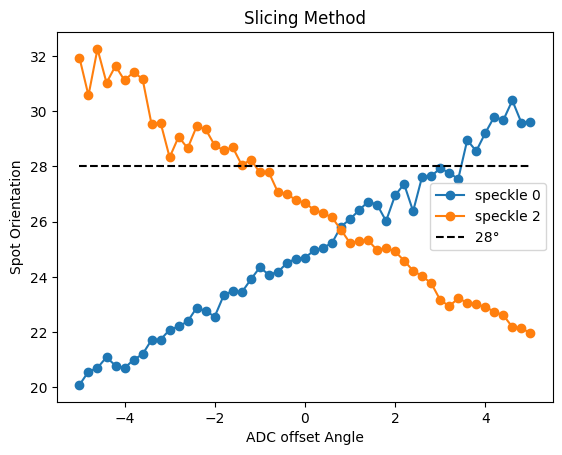

In [318]:
plt.plot(angs,angles0,'o-',label = 'speckle 0')
plt.plot(angs,angles2,'o-',label='speckle 2')
plt.hlines(28,-5,5,colors='black',linestyles='dashed',label=f'{grating_angle}°')
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title('Slicing Method')
plt.legend()

what about the same test, on a dataset with a lot less signal and a lot more noise?

### Unsaturated Lab Images
can we do the same comparison in simulation versus real life to know the size of the PSF core versus the sparkle angles using the new spot measurement method?

In [265]:
lab_unsat = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_unsat.fits')

In [300]:
angles0 = np.zeros(len(lab_unsat))
angles2 = np.zeros_like(angles0)

angle = 28
f = 47


for i, img in enumerate(lab_unsat):
    cropped = crop_image(img,400,mask_diam=30)

    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)

    angles0[i] = moment_angle(speckle0)
    angles2[i] = moment_angle(speckle2)

67.16062107305115


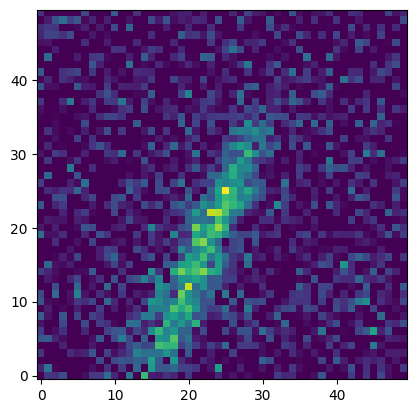

In [301]:
plt.imshow(speckle2,origin='lower')
print(angles2[-1])

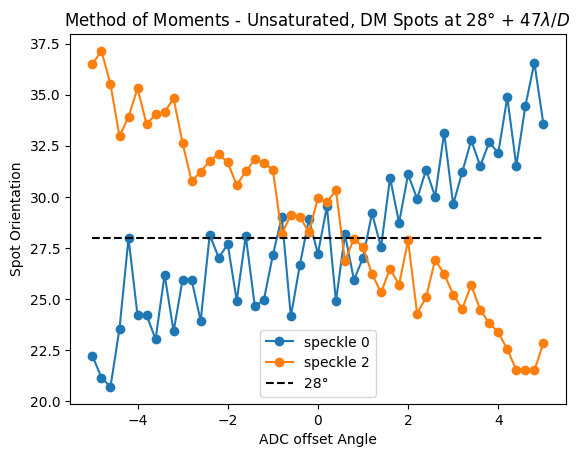

In [304]:
plt.plot(angs,90-angles0,'o-',label = 'speckle 0')
plt.plot(angs,90-angles2,'o-',label='speckle 2')
plt.hlines(28,-5,5,colors='black',linestyles='dashed', label='28°')
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title(r'Method of Moments - Unsaturated, DM Spots at 28° + 47$\lambda/D$ ')
plt.legend()

In [320]:
#old method comparison
disps = np.zeros(len(lab_unsat))
speckle_angles = []

for i, img in enumerate(lab_unsat):
    cropped = crop_image(img,450,mask_diam=30)

    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    angles = ADC.all_speckle_angles(cropped)
    speckle_angles.append(angles)

speckle_angles = np.array(speckle_angles)

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:26: RuntimeWarning: overflow encountered in exp
  return np.exp(-(x-mu)**2 / (2 * sigma2) )
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/slicing_class.py:52: OptimizeWarning: Covariance of the parameters could not be estimated
  popt = curve_fit(self.gauss,x,isolated,p0=[np.argmax(data),2])
/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/scipy/optimize/_minpack_py.py:497: RuntimeWarning: overflow encountered in matmul
  cov_x = invR @ invR.T


fitting error. could not fit speckle 3
fitting error. could not fit speckle 3
fitting error. could not fit speckle 1
fitting error. could not fit speckle 1
fitting error. could not fit speckle 1
fitting error. could not fit speckle 1


In [321]:
angles0 = speckle_angles[:,0]
angles2 = speckle_angles[:,2]

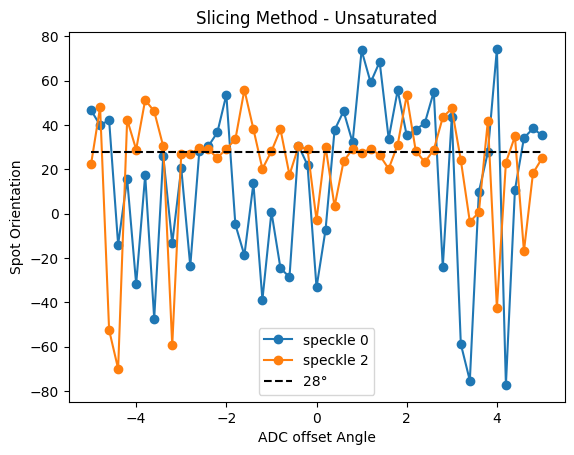

In [322]:
plt.plot(angs,angles0,'o-',label = 'speckle 0')
plt.plot(angs,angles2,'o-',label='speckle 2')
plt.hlines(28,-5,5,colors='black',linestyles='dashed',label=f'{grating_angle}°')
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title('Slicing Method - Unsaturated')
plt.legend()

### On-sky dataset

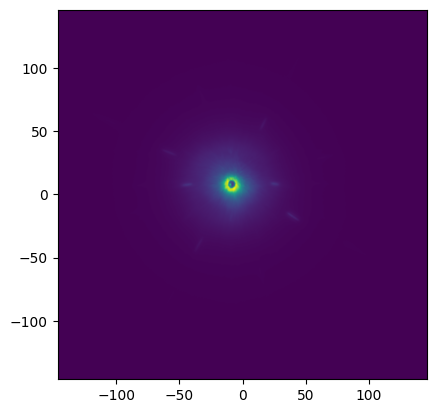

In [267]:
#import images
onsky_cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/onsky_counterrotation.fits')
imshow_field(onsky_cube[10])

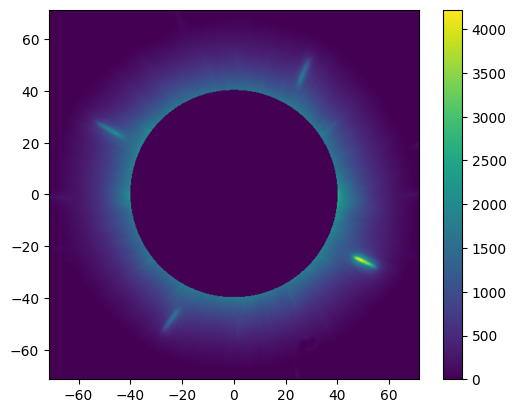

In [268]:
#crop it down and cut out a speckle
angle = 28
f = 48.5

img = onsky_cube[-1]

cropped = crop_image(img,500,mask_diam=80)

#background subtraction
bg = np.median(cropped)
cropped -= bg
cropped[cropped <0] = 0

speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
speckle1 = speckle_cutout(cropped,1,angle,f,window_size=50)
speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)
speckle3 = speckle_cutout(cropped,3,angle,f,window_size=50)

imshow_field(cropped)
plt.colorbar()

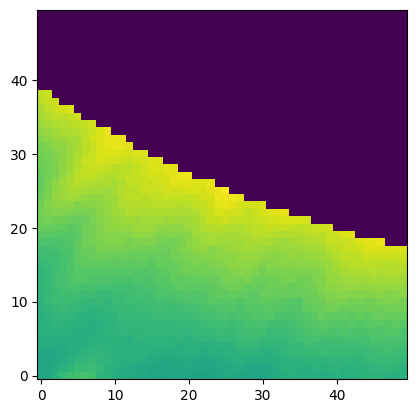

In [269]:
plt.imshow(speckle2,origin='lower')

it looks like the atmospheric halo is causing the speckle finder to not find a speckle. let's do a radial profile subtraction before masking the center to make those speckles really pop.

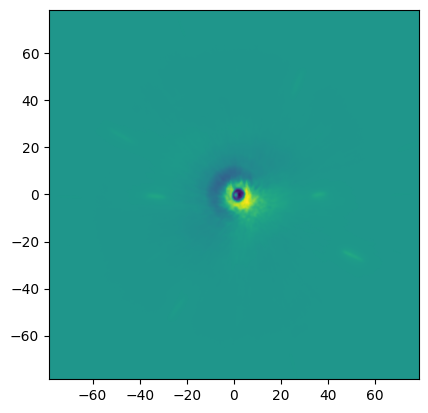

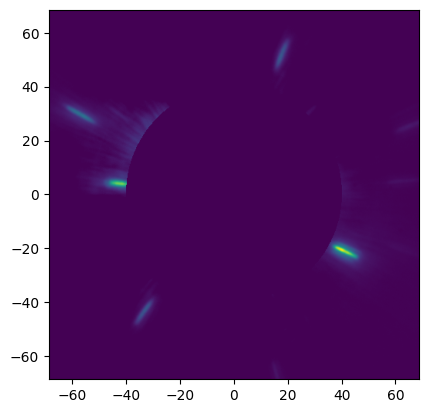

In [270]:
#Using the built-in hcipy function
cropped = crop_image(img,extent=550,mask_diam=0)
binc, profile, std_profile, ncount = radial_profile(cropped,5) 
r_coordinates = cropped.grid.as_('polar').r 
radial_map = np.interp(r_coordinates, binc, profile) 
cropped_subtracted = cropped - radial_map

imshow_field(cropped_subtracted)

cropped = crop_image(cropped_subtracted,extent=480,mask_diam=80)
plt.figure()
imshow_field(cropped)

In [271]:
#background subtraction
bg = np.median(cropped)
cropped -= bg
cropped[cropped <0] = 0

speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
speckle1 = speckle_cutout(cropped,1,angle,f,window_size=50)
speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)
speckle3 = speckle_cutout(cropped,3,angle,f,window_size=50)

Text(0.5, 1.0, 'angle: -29.46')

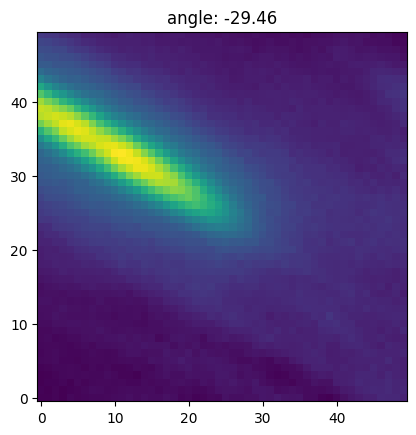

In [272]:
angle = moment_angle(speckle3)

plt.imshow(speckle3,origin='lower')
plt.title(f'angle: {angle:.2f}')

now go through the whole cube to make sure we see the right trend, and then compare it to the performance of the old algorithm in the same circumstances.

Also, the error that kills everything when you try to crop outside the range of the image is getting really annoying, so here's a new crop function to try and fix that:


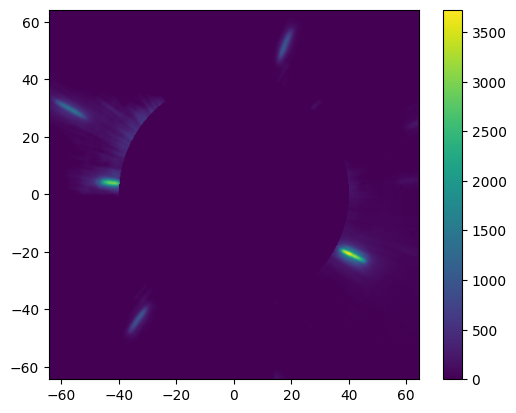

In [273]:
angle = 28
f = 48.5

img = onsky_cube[-1]

cropped = crop_image(img,512,mask_diam=0)

#radial profile subtraction for residual halo 
binc, profile, std_profile, ncount = radial_profile(cropped,5) 
r_coordinates = cropped.grid.as_('polar').r 
radial_map = np.interp(r_coordinates, binc, profile) 
cropped_subtracted = cropped - radial_map


cropped = crop_image(cropped_subtracted,extent=450,mask_diam=80)

imshow_field(cropped)

#background subtraction
bg = np.median(cropped)
cropped -= bg
cropped[cropped <0] = 0

speckle0 = speckle_cutout(cropped,0,angle,f,window_size=50)
speckle1 = speckle_cutout(cropped,1,angle,f,window_size=50)
speckle2 = speckle_cutout(cropped,2,angle,f,window_size=50)
speckle3 = speckle_cutout(cropped,3,angle,f,window_size=50)

imshow_field(cropped)
plt.colorbar()

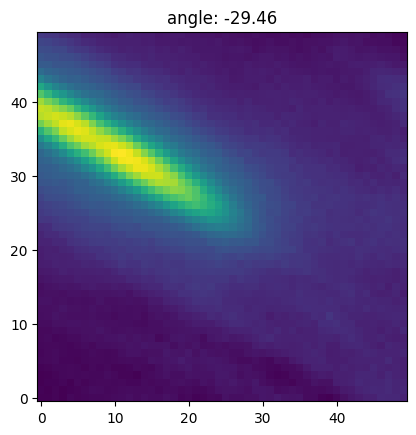

In [274]:
angle = moment_angle(speckle3)

plt.imshow(speckle3,origin='lower')
plt.title(f'angle: {angle:.2f}')
plt.show()

In [275]:
angles0 = np.zeros(len(onsky_cube))
angles2 = np.zeros_like(angles0)

angle = 28
f = 47

for i, img in enumerate(onsky_cube):
    cropped = crop_image(img,512,mask_diam=0)

    #radial profile subtraction for residual halo 
    binc, profile, std_profile, ncount = radial_profile(cropped,5) 
    r_coordinates = cropped.grid.as_('polar').r 
    radial_map = np.interp(r_coordinates, binc, profile) 
    cropped_subtracted = cropped - radial_map

    cropped = crop_image(cropped_subtracted,extent=450,mask_diam=80)
    
    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=30)

    angles0[i] = moment_angle(speckle0)
    angles2[i] = moment_angle(speckle2)

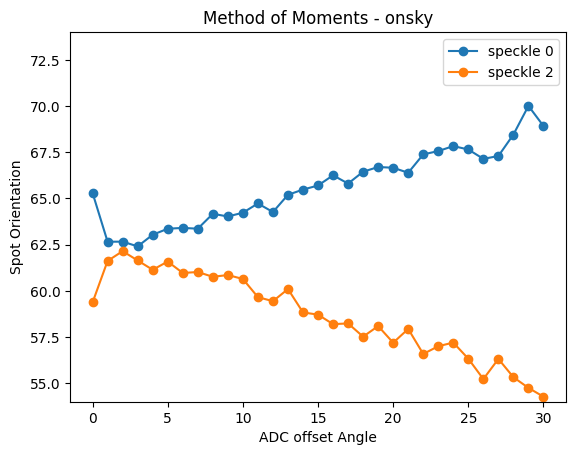

In [276]:
plt.plot(angles0,'o-',label = 'speckle 0')
plt.plot(angles2,'o-',label='speckle 2')
plt.ylim((54,74))
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title('Method of Moments - onsky')
plt.legend()

In [277]:
#same thing but with the slicing
disps = np.zeros(len(onsky_cube))
speckle_angles = []

for i, img in enumerate(onsky_cube):
    cropped = crop_image(img,512,mask_diam=0)

    #radial profile subtraction for residual halo 
    binc, profile, std_profile, ncount = radial_profile(cropped,5) 
    r_coordinates = cropped.grid.as_('polar').r 
    radial_map = np.interp(r_coordinates, binc, profile) 
    cropped_subtracted = cropped - radial_map

    cropped = crop_image(cropped_subtracted,extent=450,mask_diam=80)
    
    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    angles = ADC.all_speckle_angles(cropped)
    speckle_angles.append(angles)

speckle_angles = np.array(speckle_angles)
angles0 = speckle_angles[:,0]
angles2 = speckle_angles[:,2]

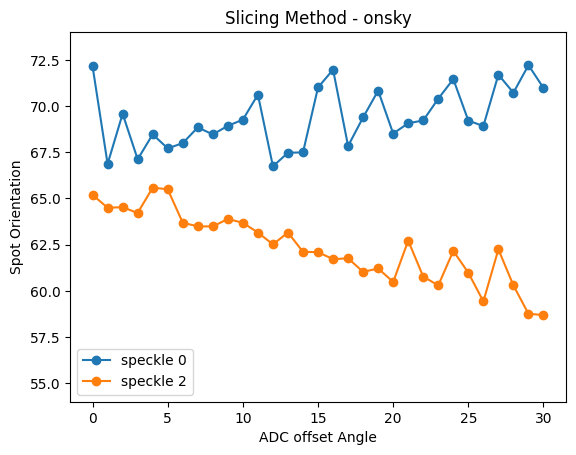

In [278]:
plt.plot(90-angles0,'o-',label = 'speckle 0')
plt.plot(90-angles2,'o-',label='speckle 2')
plt.ylim((54,74))
plt.xlabel('ADC offset Angle')
plt.ylabel('Spot Orientation')
plt.title('Slicing Method - onsky')
plt.legend()

In [279]:
#different onsky dataset, and let's put the two plots next to each other
onsky_cube = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025A/onsky_counterrotation.fits')

angles0_moment = np.zeros(len(onsky_cube))
angles2_moment = np.zeros_like(angles0_moment)
speckle_angles = []

angle = 28
f = 47

for i, img in enumerate(onsky_cube):
    cropped = crop_image(img,512,mask_diam=0)

    #radial profile subtraction for residual halo 
    binc, profile, std_profile, ncount = radial_profile(cropped,5) 
    r_coordinates = cropped.grid.as_('polar').r 
    radial_map = np.interp(r_coordinates, binc, profile) 
    cropped_subtracted = cropped - radial_map

    cropped = crop_image(cropped_subtracted,extent=450,mask_diam=80)
    
    #background subtraction
    bg = np.median(cropped)
    cropped -= bg
    cropped[cropped <0] = 0

    speckle0 = speckle_cutout(cropped,0,angle,f,window_size=30)
    speckle2 = speckle_cutout(cropped,2,angle,f,window_size=30)

    angles0_moment[i] = moment_angle(speckle0)
    angles2_moment[i] = moment_angle(speckle2)

    angles = ADC.all_speckle_angles(cropped)
    speckle_angles.append(angles)

speckle_angles = np.array(speckle_angles)
angles0_slice = speckle_angles[:,0]
angles2_slice = speckle_angles[:,2]

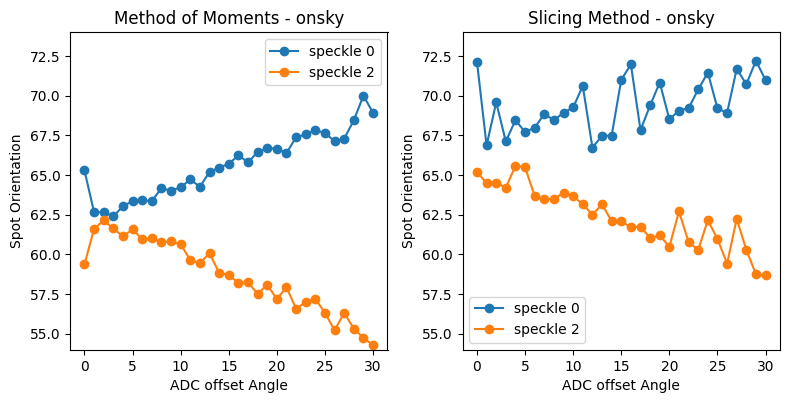

In [280]:
fig, ax = plt.subplots(1,2,figsize=(8,4))

ax[0].plot(angles0_moment,'o-',label = 'speckle 0')
ax[0].plot(angles2_moment,'o-',label='speckle 2')
ax[0].set_ylim((54,74))
ax[0].set_xlabel('ADC offset Angle')
ax[0].set_ylabel('Spot Orientation')
ax[0].set_title('Method of Moments - onsky')
ax[0].set_box_aspect(1)
ax[0].legend()

ax[1].plot(90-angles0_slice,'o-',label = 'speckle 0')
ax[1].plot(90-angles2_slice,'o-',label='speckle 2')
ax[1].set_ylim((54,74))
ax[1].set_xlabel('ADC offset Angle')
ax[1].set_ylabel('Spot Orientation')
ax[1].set_title('Slicing Method - onsky')
ax[1].set_box_aspect(1)
ax[1].legend()

fig.tight_layout()
plt.show()